# Nepal Household Survey Data Cleaning Practice


## Step 1 - Import Libraries

In [1]:
# Import the libraries we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns   

## Step 2 - Load the Data

In [2]:
# Load the CSV file into a pandas dataframe
df_raw = pd.read_csv("nepal_survey_messy.csv")

# Show the first 5 rows to understand the data
df_raw.head()

,respondent_id,district,province,age,gender,occupation,education_level,monthly_income_nrs,household_size,land_ownership_ropani,electricity_access,drinking_water_source,annual_remittance_nrs,health_insurance,mobile_phone_users,internet_access,remarks,latitude_gps,survey_notes
0,NP0001,Lalitpur,Bagmati,NaN,Male,Student,NaN,NaN,2.0,10.20,Yes,Jar Water,NaN,NaN,1,No,NaN,NaN,NaN
1,NP0002,Kathmandu,Bagmati,NaN,Female,NaN,NaN,49560.0,3.0,NaN,No,NaN,341069.0,Yes,5,No,NaN,NaN,NaN
2,NP0003,Chitwan,Gandaki,NaN,Male,Doctor,NaN,50893.0,5.0,NaN,No,NaN,104572.0,No,5,Yes,NaN,NaN,NaN
3,NP0004,Pokhara,Bagmati,73.0,Male,Government Job,NaN,25701.0,10.0,14.55,Yes,River,396315.0,Yes,4,No,NaN,27.673545,NaN
4,NP0005,Pokhara,Bagmati,28.0,Other,Doctor,NaN,NaN,NaN,16.38,No,River,NaN,No,1,No,NaN,NaN,Elderly alone


In [3]:
# Check the shape of the data
# This tells us how many rows and columns we have
print("Number of rows   :", df_raw.shape[0])
print("Number of columns:", df_raw.shape[1])

Number of rows   : 200
Number of columns: 19


In [4]:

df_raw.shape

(200, 19)

In [5]:
# Check the data types and basic info of each column
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   respondent_id          200 non-null    object 
 1   district               200 non-null    object 
 2   province               200 non-null    object 
 3   age                    160 non-null    float64
 4   gender                 200 non-null    object 
 5   occupation             112 non-null    object 
 6   education_level        104 non-null    object 
 7   monthly_income_nrs     84 non-null     float64
 8   household_size         163 non-null    float64
 9   land_ownership_ropani  87 non-null     float64
 10  electricity_access     200 non-null    object 
 11  drinking_water_source  136 non-null    object 
 12  annual_remittance_nrs  105 non-null    float64
 13  health_insurance       134 non-null    object 
 14  mobile_phone_users     200 non-null    int64  
 15  intern

## Step 3 - Find Missing Values

In [6]:
# Count how many missing values are in each column
missing_count = df_raw.isnull().sum()

# Calculate the percentage of missing values in each column
missing_percent = (missing_count / len(df_raw)) * 100

# Combine both into one table for easy viewing
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percent (%)": missing_percent.round(2)
})

# Sort by missing percentage from highest to lowest
missing_summary = missing_summary.sort_values("Missing Percent (%)", ascending=False)

# Show only columns that have at least 1 missing value
missing_summary[missing_summary["Missing Count"] > 0]

,Missing Count,Missing Percent (%)
remarks,190,95.0
survey_notes,175,87.5
latitude_gps,174,87.0
monthly_income_nrs,116,58.0
land_ownership_ropani,113,56.5
education_level,96,48.0
annual_remittance_nrs,95,47.5
occupation,88,44.0
health_insurance,66,33.0
drinking_water_source,64,32.0


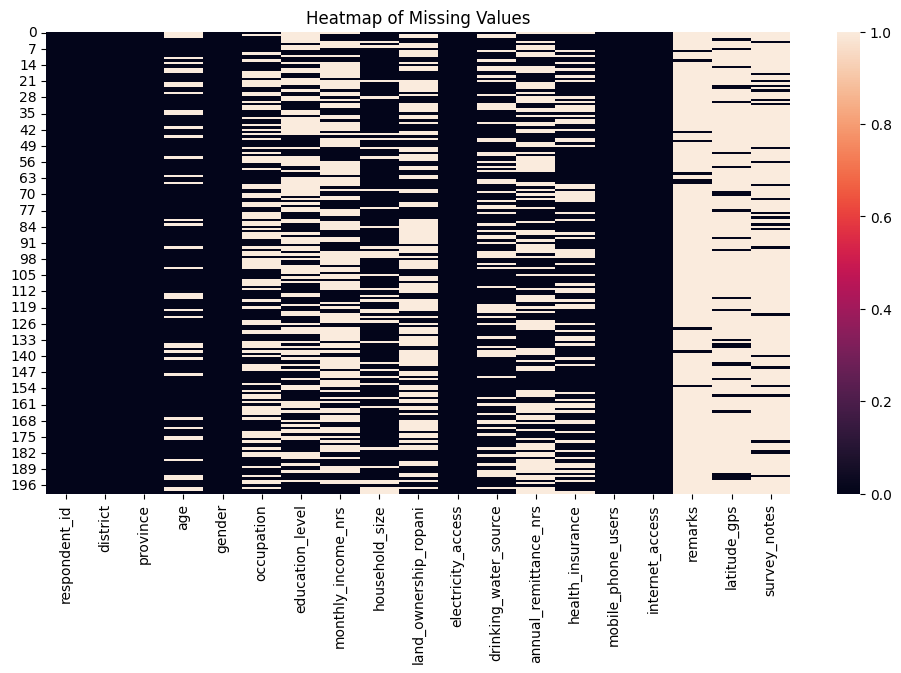

In [7]:
# heapmap of missing values
plt.figure(figsize=(12, 6))
sns.heatmap(df_raw.isnull())
plt.title("Heatmap of Missing Values")
plt.show()

## Step 4 - Make a Working Copy of the Data

We always make a copy of the original data before cleaning.
This keeps the original data safe so we can compare later.

In [8]:
# Make a copy of the original dataframe
# We will clean df_clean and keep df_raw untouched
df_clean = df_raw.copy()

print("Original dataframe shape :", df_raw.shape)
print("Copy dataframe shape      :", df_clean.shape)
print()
print("These should be equal. We are working on df_clean now.")

Original dataframe shape : (200, 19)
Copy dataframe shape      : (200, 19)

These should be equal. We are working on df_clean now.


## Step 5 - Remove Columns with More Than 80% Missing Values

Columns with too many missing values are not useful.
We drop them from the dataset.

In [9]:
# Drop the columns by typing their names directly
# We pass a list of column names inside drop()

df_clean = df_clean.drop(columns=["remarks", "survey_notes", "latitude_gps"])

print("Shape after dropping :", df_clean.shape)
print()
print("Columns removed: remarks, survey_notes, latitude_gps")

Shape after dropping : (200, 16)

Columns removed: remarks, survey_notes, latitude_gps


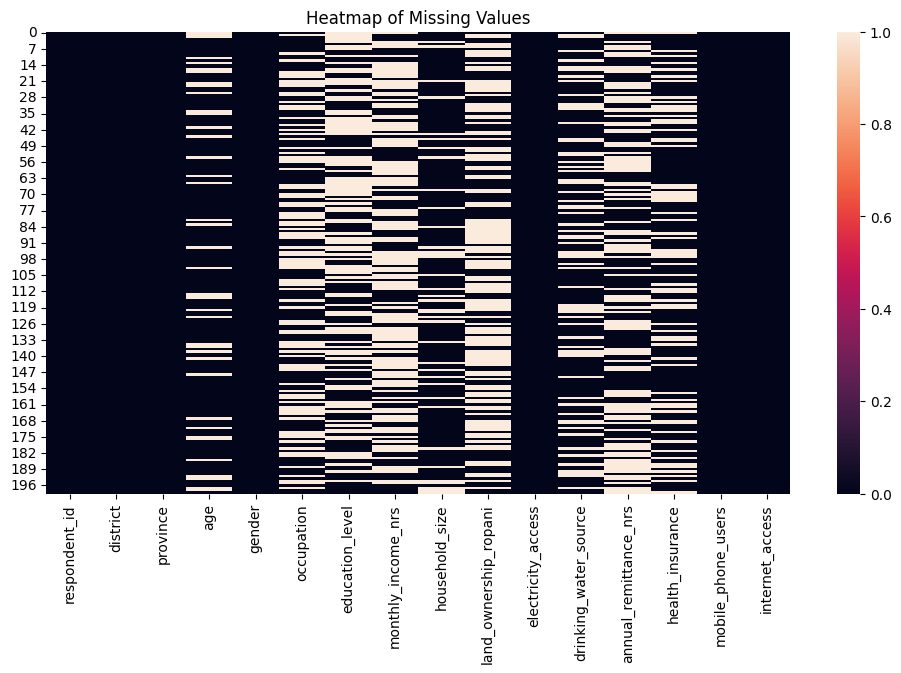

In [10]:
plt.figure(figsize=(12, 6))
sns.heatmap(df_clean.isnull())
plt.title("Heatmap of Missing Values")
plt.show()

## Step 6 - Fill Remaining Missing Values

Now we fill the missing values in the remaining columns.
We use different methods depending on the type of data.

Methods we will use:
- mean     : for numeric columns (when data is normally spread)
- median   : for numeric columns (when data has outliers)
- mode     : for text or category columns (most common value)
- ffill    : forward fill (use the value from the row above)
- bfill    : backward fill (use the value from the row below)

In [11]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   respondent_id          200 non-null    object 
 1   district               200 non-null    object 
 2   province               200 non-null    object 
 3   age                    160 non-null    float64
 4   gender                 200 non-null    object 
 5   occupation             112 non-null    object 
 6   education_level        104 non-null    object 
 7   monthly_income_nrs     84 non-null     float64
 8   household_size         163 non-null    float64
 9   land_ownership_ropani  87 non-null     float64
 10  electricity_access     200 non-null    object 
 11  drinking_water_source  136 non-null    object 
 12  annual_remittance_nrs  105 non-null    float64
 13  health_insurance       134 non-null    object 
 14  mobile_phone_users     200 non-null    int64  
 15  intern

In [12]:
df_clean.head()

,respondent_id,district,province,age,gender,occupation,education_level,monthly_income_nrs,household_size,land_ownership_ropani,electricity_access,drinking_water_source,annual_remittance_nrs,health_insurance,mobile_phone_users,internet_access
0,NP0001,Lalitpur,Bagmati,NaN,Male,Student,NaN,NaN,2.0,10.20,Yes,Jar Water,NaN,NaN,1,No
1,NP0002,Kathmandu,Bagmati,NaN,Female,NaN,NaN,49560.0,3.0,NaN,No,NaN,341069.0,Yes,5,No
2,NP0003,Chitwan,Gandaki,NaN,Male,Doctor,NaN,50893.0,5.0,NaN,No,NaN,104572.0,No,5,Yes
3,NP0004,Pokhara,Bagmati,73.0,Male,Government Job,NaN,25701.0,10.0,14.55,Yes,River,396315.0,Yes,4,No
4,NP0005,Pokhara,Bagmati,28.0,Other,Doctor,NaN,NaN,NaN,16.38,No,River,NaN,No,1,No


In [13]:
missing_count_cln = df_clean.isnull().sum()

# Calculate the percentage of missing values in each column
missing_percent_cln = (missing_count_cln / len(df_clean)) * 100
missing_percent_cln

respondent_id             0.0
district                  0.0
province                  0.0
age                      20.0
gender                    0.0
occupation               44.0
education_level          48.0
monthly_income_nrs       58.0
household_size           18.5
land_ownership_ropani    56.5
electricity_access        0.0
drinking_water_source    32.0
annual_remittance_nrs    47.5
health_insurance         33.0
mobile_phone_users        0.0
internet_access           0.0
dtype: float64

### 6a - Fill with Mean

Use mean for numeric columns with normal distribution.

Example: household_size

In [14]:
# Check missing count before filling
print("Missing in household_size before:", df_clean["household_size"].isnull().sum())

# Calculate the mean (average)
mean_value = df_clean["household_size"].mean()
print("Mean value of household_size:", round(mean_value, 2))

# Fill missing values with the mean
df_clean["household_size"] = df_clean["household_size"].fillna(mean_value)

print("Missing in household_size after :", df_clean["household_size"].isnull().sum())

Missing in household_size before: 37
Mean value of household_size: 5.64
Missing in household_size after : 0


In [15]:
avg=df_clean["land_ownership_ropani"].mean()
midd=df_clean["land_ownership_ropani"].median()

print(avg , midd)

9.637011494252874 9.23


In [16]:
avg=df_clean["monthly_income_nrs"].mean()
midd=df_clean["monthly_income_nrs"].median()

print(avg , midd)

74624.42857142857 72828.0


In [17]:
avg=df_clean["annual_remittance_nrs"].mean()
midd=df_clean["annual_remittance_nrs"].median()

print(avg , midd)

259076.9619047619 250705.0


### 6b - Fill with Median

Use median for numeric columns that have outliers.

Example: monthly_income_nrs, land_ownership_ropani, annual_remittance_nrs

In [18]:
# Fill monthly_income_nrs with median
print("Missing in monthly_income_nrs before:", df_clean["monthly_income_nrs"].isnull().sum())

median_income = df_clean["monthly_income_nrs"].median()
print("Median monthly income (NRS):", median_income)

df_clean["monthly_income_nrs"] = df_clean["monthly_income_nrs"].fillna(median_income)

print("Missing in monthly_income_nrs after :", df_clean["monthly_income_nrs"].isnull().sum())

Missing in monthly_income_nrs before: 116
Median monthly income (NRS): 72828.0
Missing in monthly_income_nrs after : 0


In [19]:
# Fill land_ownership_ropani with median
print("Missing in land_ownership_ropani before:", df_clean["land_ownership_ropani"].isnull().sum())

median_land = df_clean["land_ownership_ropani"].median()
df_clean["land_ownership_ropani"] = df_clean["land_ownership_ropani"].fillna(median_land)

print("Missing in land_ownership_ropani after :", df_clean["land_ownership_ropani"].isnull().sum())

Missing in land_ownership_ropani before: 113
Missing in land_ownership_ropani after : 0


In [20]:
# Fill annual_remittance_nrs with median
print("Missing in annual_remittance_nrs before:", df_clean["annual_remittance_nrs"].isnull().sum())

median_remittance = df_clean["annual_remittance_nrs"].median()
df_clean["annual_remittance_nrs"] = df_clean["annual_remittance_nrs"].fillna(median_remittance)

print("Missing in annual_remittance_nrs after :", df_clean["annual_remittance_nrs"].isnull().sum())

Missing in annual_remittance_nrs before: 95
Missing in annual_remittance_nrs after : 0


In [21]:
# Fill age with median
# Age can sometimes have extreme values so median is better
print("Missing in age before:", df_clean["age"].isnull().sum())

median_age = df_clean["age"].median()
df_clean["age"] = df_clean["age"].fillna(median_age)

print("Missing in age after :", df_clean["age"].isnull().sum())

Missing in age before: 40
Missing in age after : 0


In [22]:
df_clean.head()

,respondent_id,district,province,age,gender,occupation,education_level,monthly_income_nrs,household_size,land_ownership_ropani,electricity_access,drinking_water_source,annual_remittance_nrs,health_insurance,mobile_phone_users,internet_access
0,NP0001,Lalitpur,Bagmati,49.0,Male,Student,NaN,72828.0,2.000000,10.20,Yes,Jar Water,250705.0,NaN,1,No
1,NP0002,Kathmandu,Bagmati,49.0,Female,NaN,NaN,49560.0,3.000000,9.23,No,NaN,341069.0,Yes,5,No
2,NP0003,Chitwan,Gandaki,49.0,Male,Doctor,NaN,50893.0,5.000000,9.23,No,NaN,104572.0,No,5,Yes
3,NP0004,Pokhara,Bagmati,73.0,Male,Government Job,NaN,25701.0,10.000000,14.55,Yes,River,396315.0,Yes,4,No
4,NP0005,Pokhara,Bagmati,28.0,Other,Doctor,NaN,72828.0,5.638037,16.38,No,River,250705.0,No,1,No


In [23]:
df_clean["education_level"].value_counts()

education_level
SLC                    20
Bachelors              19
Masters                15
No Formal Education    15
Secondary              14
Primary                12
Intermediate            9
Name: count, dtype: int64

### 6c - Fill with Mode

Use mode for text or category columns.
Mode means the most common value in that column.

Example: education_level, occupation

In [24]:
# Fill education_level with mode
print("Missing in education_level before:", df_clean["education_level"].isnull().sum())

# mode() returns a series, we take the first value [0]
mode_education = df_clean["education_level"].mode()[0]
print("Most common education level:", mode_education)

df_clean["education_level"] = df_clean["education_level"].fillna(mode_education)

print("Missing in education_level after :", df_clean["education_level"].isnull().sum())

Missing in education_level before: 96
Most common education level: SLC
Missing in education_level after : 0


In [25]:
df_clean["occupation"].value_counts()

occupation
Daily Wage        23
Business          18
Engineer          16
Doctor            13
Student           12
Teacher           12
Government Job    11
Farmer             7
Name: count, dtype: int64

In [26]:
# Fill occupation with mode
print("Missing in occupation before:", df_clean["occupation"].isnull().sum())

mode_occupation = df_clean["occupation"].mode()[0]
print("Most common occupation:", mode_occupation)

df_clean["occupation"] = df_clean["occupation"].fillna(mode_occupation)

print("Missing in occupation after :", df_clean["occupation"].isnull().sum())

Missing in occupation before: 88
Most common occupation: Daily Wage
Missing in occupation after : 0


### 6d - Fill with Forward Fill (ffill)

ffill copies the value from the row above.
Good for ordered data like survey forms filled in sequence.

Example: health_insurance

In [27]:
# Fill health_insurance using forward fill
print("Missing in health_insurance before:", df_clean["health_insurance"].isnull().sum())

df_clean["health_insurance"] = df_clean["health_insurance"].ffill()

print("Missing in health_insurance after :", df_clean["health_insurance"].isnull().sum())

Missing in health_insurance before: 66
Missing in health_insurance after : 1


### 6e - Fill with Backward Fill (bfill)

bfill copies the value from the row below.
Useful when the next known value is a better estimate.

Example: drinking_water_source

In [28]:
df_clean["drinking_water_source"].value_counts()

drinking_water_source
River        41
Jar Water    40
Well         31
Tap          24
Name: count, dtype: int64

In [29]:
# Fill drinking_water_source using backward fill
print("Missing in drinking_water_source before:", df_clean["drinking_water_source"].isnull().sum())

df_clean["drinking_water_source"] = df_clean["drinking_water_source"].bfill()

print("Missing in drinking_water_source after :", df_clean["drinking_water_source"].isnull().sum())

Missing in drinking_water_source before: 64
Missing in drinking_water_source after : 0


## Step 7 - Check the Result

In [30]:
# Check if there are any missing values left
total_missing = df_clean.isnull().sum().sum()
print("Total missing values remaining in df_clean:", total_missing)

if total_missing == 0:
    print("All missing values have been handled.")
else:
    print("Some missing values still remain. Check the columns below:")
    print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Total missing values remaining in df_clean: 1
Some missing values still remain. Check the columns below:
health_insurance    1
dtype: int64


In [31]:
# Compare original and cleaned dataframe
print("Original data shape :", df_raw.shape)
print("Cleaned data shape  :", df_clean.shape)
print()
print("Original missing values total :", df_raw.isnull().sum().sum())
print("Cleaned missing values total  :", df_clean.isnull().sum().sum())

Original data shape : (200, 19)
Cleaned data shape  : (200, 16)

Original missing values total : 1254
Cleaned missing values total  : 1


In [32]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   respondent_id          200 non-null    object 
 1   district               200 non-null    object 
 2   province               200 non-null    object 
 3   age                    200 non-null    float64
 4   gender                 200 non-null    object 
 5   occupation             200 non-null    object 
 6   education_level        200 non-null    object 
 7   monthly_income_nrs     200 non-null    float64
 8   household_size         200 non-null    float64
 9   land_ownership_ropani  200 non-null    float64
 10  electricity_access     200 non-null    object 
 11  drinking_water_source  200 non-null    object 
 12  annual_remittance_nrs  200 non-null    float64
 13  health_insurance       199 non-null    object 
 14  mobile_phone_users     200 non-null    int64  
 15  intern

In [33]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   respondent_id          200 non-null    object 
 1   district               200 non-null    object 
 2   province               200 non-null    object 
 3   age                    160 non-null    float64
 4   gender                 200 non-null    object 
 5   occupation             112 non-null    object 
 6   education_level        104 non-null    object 
 7   monthly_income_nrs     84 non-null     float64
 8   household_size         163 non-null    float64
 9   land_ownership_ropani  87 non-null     float64
 10  electricity_access     200 non-null    object 
 11  drinking_water_source  136 non-null    object 
 12  annual_remittance_nrs  105 non-null    float64
 13  health_insurance       134 non-null    object 
 14  mobile_phone_users     200 non-null    int64  
 15  intern

In [34]:
# Show first few rows of cleaned data
df_clean.head(10)

,respondent_id,district,province,age,gender,occupation,education_level,monthly_income_nrs,household_size,land_ownership_ropani,electricity_access,drinking_water_source,annual_remittance_nrs,health_insurance,mobile_phone_users,internet_access
0,NP0001,Lalitpur,Bagmati,49.0,Male,Student,SLC,72828.0,2.000000,10.20,Yes,Jar Water,250705.0,NaN,1,No
1,NP0002,Kathmandu,Bagmati,49.0,Female,Daily Wage,SLC,49560.0,3.000000,9.23,No,River,341069.0,Yes,5,No
2,NP0003,Chitwan,Gandaki,49.0,Male,Doctor,SLC,50893.0,5.000000,9.23,No,River,104572.0,No,5,Yes
3,NP0004,Pokhara,Bagmati,73.0,Male,Government Job,SLC,25701.0,10.000000,14.55,Yes,River,396315.0,Yes,4,No
4,NP0005,Pokhara,Bagmati,28.0,Other,Doctor,SLC,72828.0,5.638037,16.38,No,River,250705.0,No,1,No
5,NP0006,Bhaktapur,Lumbini,69.0,Other,Business,Masters,72828.0,9.000000,9.23,Yes,Jar Water,168384.0,Yes,1,No
6,NP0007,Lalitpur,Bagmati,69.0,Female,Daily Wage,SLC,72828.0,5.638037,9.23,No,Well,250705.0,No,5,No
7,NP0008,Nepalgunj,Madhesh,29.0,Male,Daily Wage,SLC,42517.0,7.000000,2.93,Yes,Jar Water,250705.0,No,3,Yes
8,NP0009,Lalitpur,Gandaki,74.0,Other,Government Job,SLC,65866.0,10.000000,9.23,Yes,Jar Water,31018.0,No,5,No
9,NP0010,Hetauda,Lumbini,44.0,Male,Daily Wage,Masters,125887.0,9.000000,9.23,No,Jar Water,250705.0,No,3,No


## Step 8 - Save the Cleaned Data to CSV

In [35]:
# Save the cleaned dataframe to a new CSV file
df_clean.to_csv("nepal_survey_cleaned.csv", index=False)

print("Cleaned data saved as: nepal_survey_cleaned.csv")
print("Shape of saved file  :", df_clean.shape)

Cleaned data saved as: nepal_survey_cleaned.csv
Shape of saved file  : (200, 16)


## Summary

Here is what we did in this notebook:

1. Loaded the messy Nepal survey data into a pandas dataframe
2. Counted missing values as numbers and as percentages
3. Made a copy of the original data to work on safely
4. Dropped columns with more than 80% missing values
5. Filled remaining missing values using:
   - mean for household_size
   - median for monthly_income_nrs, land_ownership_ropani, annual_remittance_nrs, age
   - mode for education_level, occupation
   - ffill for health_insurance
   - bfill for drinking_water_source
6. Verified that no missing values remain
7. Saved the cleaned data to a new CSV file

This is the basic workflow for data cleaning in a real project.

##Visualization

In [36]:
df1=pd.read_csv("nepal_survey_cleaned.csv")

In [38]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   respondent_id          200 non-null    object 
 1   district               200 non-null    object 
 2   province               200 non-null    object 
 3   age                    200 non-null    float64
 4   gender                 200 non-null    object 
 5   occupation             200 non-null    object 
 6   education_level        200 non-null    object 
 7   monthly_income_nrs     200 non-null    float64
 8   household_size         200 non-null    float64
 9   land_ownership_ropani  200 non-null    float64
 10  electricity_access     200 non-null    object 
 11  drinking_water_source  200 non-null    object 
 12  annual_remittance_nrs  200 non-null    float64
 13  health_insurance       199 non-null    object 
 14  mobile_phone_users     200 non-null    int64  
 15  intern

In [39]:
df1.head()

,respondent_id,district,province,age,gender,occupation,education_level,monthly_income_nrs,household_size,land_ownership_ropani,electricity_access,drinking_water_source,annual_remittance_nrs,health_insurance,mobile_phone_users,internet_access
0,NP0001,Lalitpur,Bagmati,49.0,Male,Student,SLC,72828.0,2.000000,10.20,Yes,Jar Water,250705.0,NaN,1,No
1,NP0002,Kathmandu,Bagmati,49.0,Female,Daily Wage,SLC,49560.0,3.000000,9.23,No,River,341069.0,Yes,5,No
2,NP0003,Chitwan,Gandaki,49.0,Male,Doctor,SLC,50893.0,5.000000,9.23,No,River,104572.0,No,5,Yes
3,NP0004,Pokhara,Bagmati,73.0,Male,Government Job,SLC,25701.0,10.000000,14.55,Yes,River,396315.0,Yes,4,No
4,NP0005,Pokhara,Bagmati,28.0,Other,Doctor,SLC,72828.0,5.638037,16.38,No,River,250705.0,No,1,No


In [40]:
df1["district"].value_counts()

district
Pokhara       27
Lalitpur      26
Nepalgunj     25
Chitwan       20
Bhaktapur     18
Hetauda       18
Butwal        18
Kathmandu     17
Dharan        17
Biratnagar    14
Name: count, dtype: int64

In [47]:
df1["province"].value_counts()

province
Bagmati    49
Gandaki    41
Madhesh    40
Lumbini    35
Koshi      35
Name: count, dtype: int64

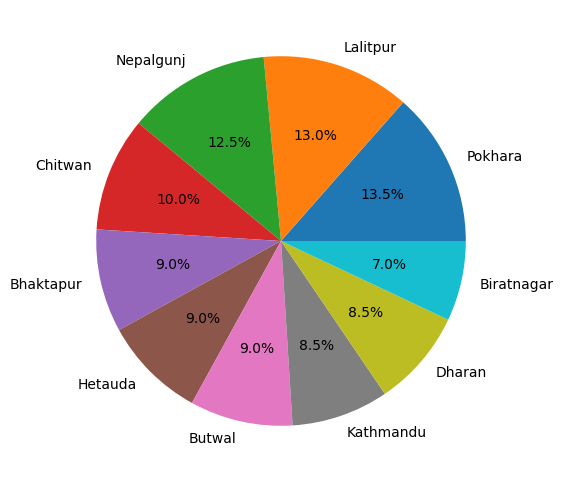

In [49]:
dist_counts = df1["district"].value_counts()

plt.figure(figsize=(12, 6)) 
plt.pie(dist_counts, labels=dist_counts.index, autopct='%1.1f%%')
plt.show()

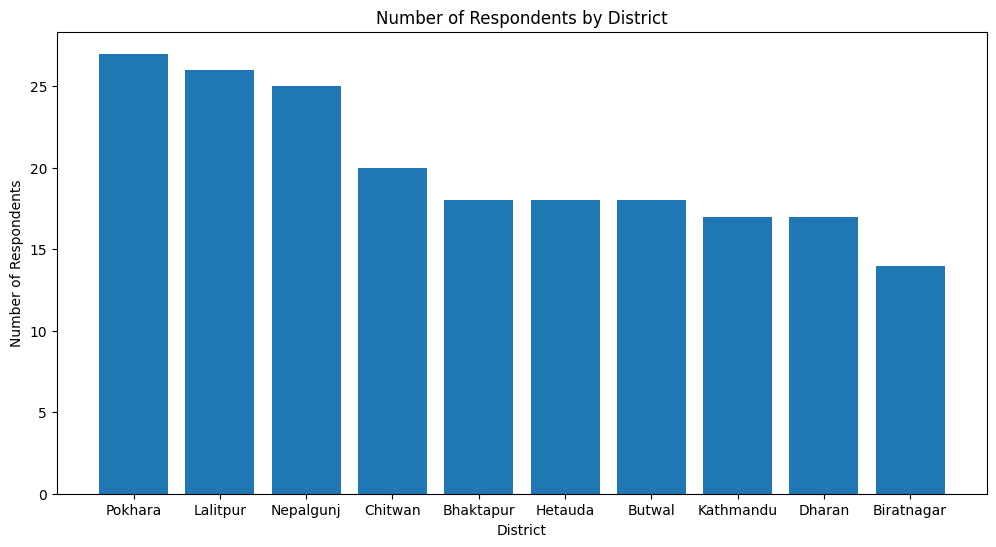

In [50]:
plt.figure(figsize=(12, 6))
plt.bar(dist_counts.index, dist_counts.values)
plt.title("Number of Respondents by District")
plt.xlabel("District")
plt.ylabel("Number of Respondents")
plt.show()

In [51]:
df1.head()

,respondent_id,district,province,age,gender,occupation,education_level,monthly_income_nrs,household_size,land_ownership_ropani,electricity_access,drinking_water_source,annual_remittance_nrs,health_insurance,mobile_phone_users,internet_access
0,NP0001,Lalitpur,Bagmati,49.0,Male,Student,SLC,72828.0,2.000000,10.20,Yes,Jar Water,250705.0,NaN,1,No
1,NP0002,Kathmandu,Bagmati,49.0,Female,Daily Wage,SLC,49560.0,3.000000,9.23,No,River,341069.0,Yes,5,No
2,NP0003,Chitwan,Gandaki,49.0,Male,Doctor,SLC,50893.0,5.000000,9.23,No,River,104572.0,No,5,Yes
3,NP0004,Pokhara,Bagmati,73.0,Male,Government Job,SLC,25701.0,10.000000,14.55,Yes,River,396315.0,Yes,4,No
4,NP0005,Pokhara,Bagmati,28.0,Other,Doctor,SLC,72828.0,5.638037,16.38,No,River,250705.0,No,1,No


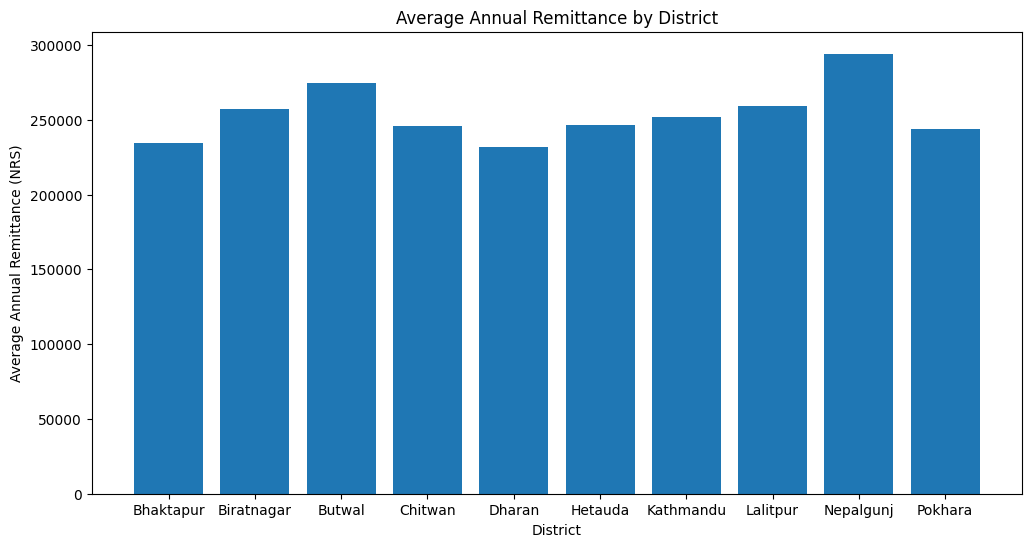

In [54]:
#district wise annual  remmitance using groupby
dist_remittance = df1.groupby('district')['annual_remittance_nrs'].mean()

plt.figure(figsize=(12, 6))
#dist_remittance.plot(kind='bar')
plt.bar(dist_remittance.index, dist_remittance.values)
plt.title("Average Annual Remittance by District")
plt.xlabel("District")
plt.ylabel("Average Annual Remittance (NRS)")
plt.show()